# Airedale Data Analysis

## Section 0 Foundation

This notebook analyzes the team's combined dataset, produced from the
five original datasets by the data-cleaning pipeline.

Before modeling, we check the data structure, investigate relationships
between cost columns, and state our cost assumptions.

In [10]:
import pandas as pd

combined = pd.read_excel(
    "DataSets/Competition_Dataset_Final.xlsx"
)

print("Rows:", len(combined))
print("Columns:", len(combined.columns))
print("Unique serial numbers:", combined["Serial Number"].nunique())
print("Missing serial numbers:", combined["Serial Number"].isna().sum())

Rows: 3000
Columns: 24
Unique serial numbers: 3000
Missing serial numbers: 0


In [11]:
cost_difference = (
    combined["Warranty Cost"]
    - 2 * combined["Repair Cost Field Service"]
)

cost_difference.value_counts().sort_index()

0    1565
1    1435
Name: count, dtype: int64

## Initial audit finding

Warranty Cost equals twice Repair Cost Field Service for 1,565 units.
For the remaining 1,435 units, it equals twice that cost plus $1.

This is consistent with rounding, but the dataset does not explain
the accounting relationship between these two columns.

## Initial cost definitions

- Use Warranty Cost as the primary measure of recorded warranty expense.
- Track field-service repair cost separately because its overlap with
  warranty cost is unclear.
- Report downtime and labor in hours until an hourly cost is justified.
- Keep factory material costs separate while investigating whether any
  expenses overlap.
- Treat a three-year projection as a scenario requiring explicit
  assumptions about future case volume and timing.

## Remaining data audit

Check whether warranty eligibility and final test outcomes vary.
Also inspect the relationship between claim dates and service dates.

These checks determine which questions the dataset can answer.

In [12]:
original_service = pd.read_excel(
    "DataSets/Competition_Dataset1_Field_Service_Final.xlsx"
)

original_eolt = pd.read_excel(
    "DataSets/Competition_Dataset5_EOLT_Final.xlsx"
)

print("Warranty eligibility:")
print(original_service["Warranty Eligible"].value_counts(dropna=False))

print("\nPassed after repair:")
print(original_eolt["Pass After Repair"].value_counts(dropna=False))

print("\nRetested:")
print(original_eolt["Retested"].value_counts(dropna=False))

print("\nRecords with positive warranty cost:")
print((combined["Warranty Cost"] > 0).sum())

Warranty eligibility:
Warranty Eligible
Yes    3000
Name: count, dtype: int64

Passed after repair:
Pass After Repair
Yes    3000
Name: count, dtype: int64

Retested:
Retested
Yes    3000
Name: count, dtype: int64

Records with positive warranty cost:
3000


In [13]:
service_dates = pd.to_datetime(
    combined["Service Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

claim_dates = pd.to_datetime(
    combined["Claim Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Unrecognized service dates:", service_dates.isna().sum())
print("Unrecognized claim dates:", claim_dates.isna().sum())

print("Claim before service:", (claim_dates < service_dates).sum())
print("Claim on service date:", (claim_dates == service_dates).sum())
print("Claim after service:", (claim_dates > service_dates).sum())

Unrecognized service dates: 0
Unrecognized claim dates: 0
Claim before service: 1440
Claim on service date: 11
Claim after service: 1549


## Audit implications

- Warranty Eligible, Pass After Repair, and Retested are Yes for every
  supplied record. They cannot distinguish outcomes within this sample.
- Every supplied unit has a positive recorded warranty cost. The data
  does not include a comparison group of units without warranty claims.
- Pass After Repair does not establish whether a unit passed its first
  test, so these records cannot establish overall first-pass yield.
- Both date columns parse successfully. Claim dates precede service dates
  for 1,440 units, but their business definitions need clarification.
- We will not use claim or service dates as manufacturing dates.
- Initial predictive results will describe outcomes among the supplied
  failure cases, rather than failure probability across all production.

## Section 1.1 Facility and supplier associations

Question: How does the proportion of leak-related cases differ depending
on whether a unit comes from Facility 2, uses Supplier B, or both?

These comparisons describe the supplied failure cases. They do not
establish production-wide failure rates or prove causes.

In [15]:
leak_check = combined.assign(
    facility_2=combined["Facility"] == "Facility 2",
    supplier_b=combined["Coil Supplier"] == "Supplier B",
    leak=combined["Failure Category"] == "Leak"
)

leak_summary = (
    leak_check.groupby(["facility_2", "supplier_b"])["leak"]
    .agg(["count", "sum", "mean"])
)

leak_summary["mean"] = leak_summary["mean"] * 100
leak_summary.columns = ["Cases", "Leak Cases", "Leak (%)"]

leak_summary

Cases  Leak Cases   Leak (%)
facility_2 supplier_b                              
False      False        1570           0   0.000000
           True          646         356  55.108359
True       False         536         290  54.104478
           True          248         142  57.258065

In [16]:
family_leaks = (
    leak_check.groupby(
        ["Product Family", "facility_2", "supplier_b"]
    )["leak"]
    .agg(["count", "sum", "mean"])
)

family_leaks["mean"] = family_leaks["mean"] * 100
family_leaks.columns = ["Cases", "Leak Cases", "Leak (%)"]

family_leaks.round(2)

Cases  Leak Cases  Leak (%)
Product Family facility_2 supplier_b                             
DC100          False      False         396           0      0.00
                          True          154          91     59.09
               True       False         132          75     56.82
                          True           57          34     59.65
DC200          False      False         395           0      0.00
                          True          174          93     53.45
               True       False         141          74     52.48
                          True           61          32     52.46
DC300          False      False         479           0      0.00
                          True          204         108     52.94
               True       False         159          89     55.97
                          True           82          50     60.98
LegacyX        False      False         300           0      0.00
                          True          114          64     56.14
               True       False         104          52     50.00
                          True           48          26     54.17

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from pathlib import Path

figures = Path("Figures")
figures.mkdir(exist_ok=True)

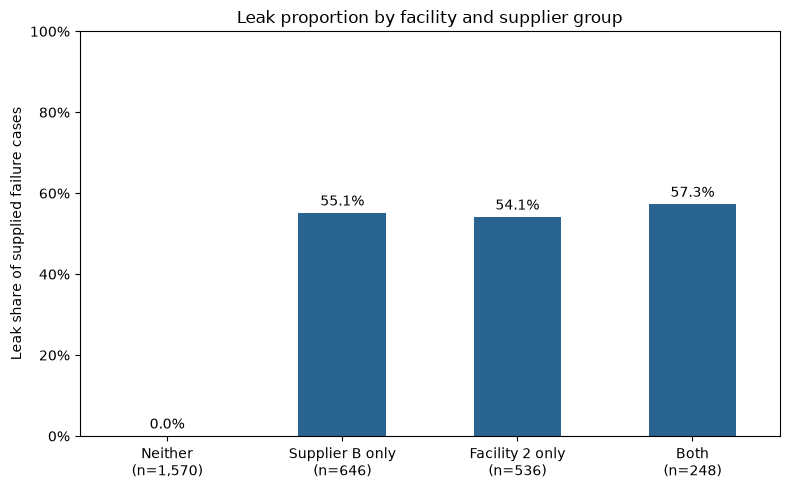

In [18]:
exposure_plot = leak_summary.reindex([
    (False, False),
    (False, True),
    (True, False),
    (True, True)
])

names = ["Neither", "Supplier B only", "Facility 2 only", "Both"]

ax = exposure_plot["Leak (%)"].plot.bar(
    figsize=(8, 5),
    color="#28648F"
)

ax.set_xticklabels(
    [f"{name}\n(n={n:,})"
     for name, n in zip(names, exposure_plot["Cases"])],
    rotation=0
)

ax.set(
    title="Leak proportion by facility and supplier group",
    xlabel="",
    ylabel="Leak share of supplied failure cases",
    ylim=(0, 100)
)

ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(figures / "leak_by_exposure.png", dpi=300)
plt.show()

,Cases,Leak Cases,Leak (%)
Product Family,,,
DC100,739,200,27.06
DC200,771,199,25.81
DC300,924,247,26.73
LegacyX,566,142,25.09


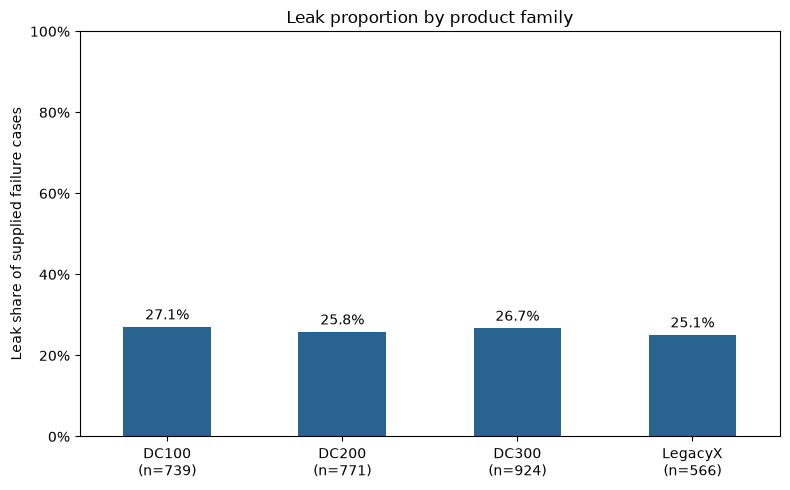

In [20]:
family_summary = (
    combined.assign(leak=combined["Failure Category"] == "Leak")
    .groupby("Product Family")["leak"]
    .agg(["count", "sum", "mean"])
)

family_summary.columns = ["Cases", "Leak Cases", "Leak (%)"]
family_summary["Leak (%)"] = family_summary["Leak (%)"] * 100

display(family_summary.round(2))

ax = family_summary["Leak (%)"].plot.bar(
    figsize=(8, 5),
    color="#28648F"
)

ax.set_xticklabels(
    [f"{name}\n(n={n:,})"
     for name, n in zip(family_summary.index, family_summary["Cases"])],
    rotation=0
)

ax.set(
    title="Leak proportion by product family",
    xlabel="",
    ylabel="Leak share of supplied failure cases",
    ylim=(0, 100)
)

ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(figures / "leak_by_family.png", dpi=300)
plt.show()

,count,mean
Product Family,,
DC100,200,6836.10
DC200,199,6836.05
DC300,247,6580.61
LegacyX,142,10080.44


LegacyX average: $10,080.44
Other families pooled average: $6,738.39
LegacyX average is 49.6% higher.


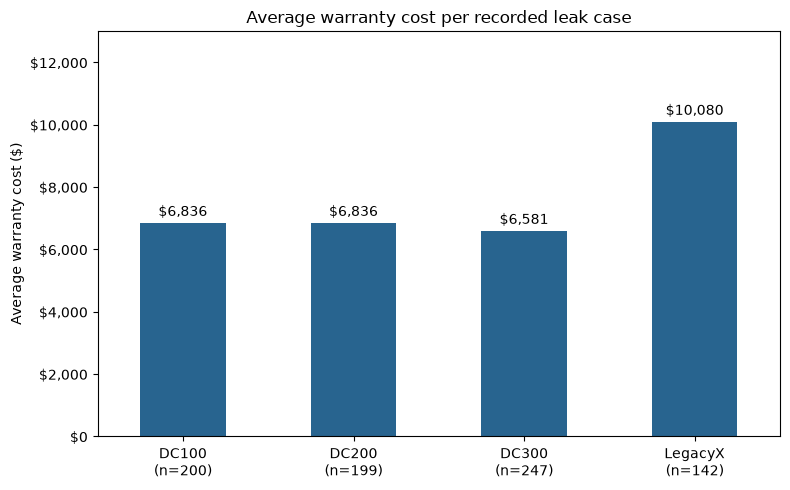

In [21]:
# Keep only records involving leaks.
leak_cases = combined[combined["Failure Category"] == "Leak"]

leak_costs = (
    leak_cases.groupby("Product Family")["Warranty Cost"]
    .agg(["count", "mean"])
)

display(leak_costs.round(2))

# Compare LegacyX with all other leak cases pooled together.
legacy_average = leak_cases.loc[
    leak_cases["Product Family"] == "LegacyX", "Warranty Cost"
].mean()

other_average = leak_cases.loc[
    leak_cases["Product Family"] != "LegacyX", "Warranty Cost"
].mean()

percent_higher = (legacy_average / other_average - 1) * 100

print(f"LegacyX average: ${legacy_average:,.2f}")
print(f"Other families pooled average: ${other_average:,.2f}")
print(f"LegacyX average is {percent_higher:.1f}% higher.")

ax = leak_costs["mean"].plot.bar(
    figsize=(8, 5),
    color="#28648F"
)

ax.set_xticklabels(
    [f"{name}\n(n={n:,})"
     for name, n in zip(leak_costs.index, leak_costs["count"])],
    rotation=0
)

ax.set(
    title="Average warranty cost per recorded leak case",
    xlabel="",
    ylabel="Average warranty cost ($)",
    ylim=(0, 13000)
)

ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.bar_label(
    ax.containers[0],
    labels=[f"${value:,.0f}" for value in leak_costs["mean"]],
    padding=3
)

plt.tight_layout()
plt.savefig(figures / "leak_cost_by_family.png", dpi=300)
plt.show()

### Interpretation of leak associations

Leak proportions are similar across product families, at approximately
25–27%. Facility 2 and Supplier B show much stronger associations with
leaks in the supplied failure cases.

Product family remains relevant to cost: LegacyX leak cases have
approximately 50% higher average warranty costs than other families.

These findings describe associations within the supplied failure cases.
They do not establish causes or production-wide failure rates.

## Section 1.2 Controls revision

Compare the proportion of Controls failures across revisions.
Check the comparison within product families and calculate the recorded
warranty expense associated with Controls failures.

In [22]:
controls_check = combined.assign(
    controls=combined["Failure Category"] == "Controls"
)

controls_summary = (
    controls_check.groupby("Controls Revision")["controls"]
    .agg(["count", "sum", "mean"])
)

controls_summary.columns = ["Cases", "Controls Cases", "Controls (%)"]
controls_summary["Controls (%)"] *= 100

controls_cost = combined.loc[
    combined["Failure Category"] == "Controls", "Warranty Cost"
].sum()

display(controls_summary.round(2))
print(f"Recorded Controls warranty expense: ${controls_cost:,.0f}")

,Cases,Controls Cases,Controls (%)
Controls Revision,,,
Rev A,894,283,31.66
Rev B,1041,0,0.00
Rev C,1065,0,0.00


Recorded Controls warranty expense: $785,109


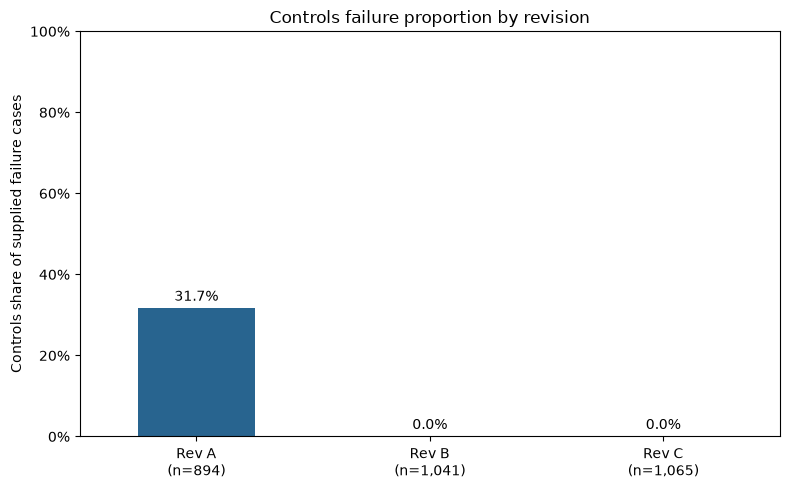

In [23]:
ax = controls_summary["Controls (%)"].plot.bar(
    figsize=(8, 5),
    color="#28648F"
)

ax.set_xticklabels(
    [f"{revision}\n(n={n:,})"
     for revision, n in zip(
         controls_summary.index, controls_summary["Cases"]
     )],
    rotation=0
)

ax.set(
    title="Controls failure proportion by revision",
    xlabel="",
    ylabel="Controls share of supplied failure cases",
    ylim=(0, 100)
)

ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(figures / "controls_by_revision.png", dpi=300)
plt.show()

In [25]:
family_controls = (
    controls_check.groupby(
        ["Product Family", "Controls Revision"]
    )["controls"]
    .agg(["count", "sum", "mean"])
)

family_controls.columns = ["Cases", "Controls Cases", "Controls (%)"]
family_controls["Controls (%)"] *= 100

family_controls.reset_index().round(2)

,Product Family,Controls Revision,Cases,Controls Cases,Controls (%)
0,DC100,Rev A,194,59,30.41
1,DC100,Rev B,269,0,0.00
2,DC100,Rev C,276,0,0.00
3,DC200,Rev A,234,91,38.89
4,DC200,Rev B,257,0,0.00
5,DC200,Rev C,280,0,0.00
6,DC300,Rev A,290,82,28.28
7,DC300,Rev B,326,0,0.00
8,DC300,Rev C,308,0,0.00
9,LegacyX,Rev A,176,51,28.98


### Interpretation

All 283 recorded Controls failures involve Rev A units. Rev B and Rev C
have no recorded Controls failures in this sample. This pattern holds
within all four product families.

Controls failures account for $785,109 in recorded warranty expense.

Rev A is associated with Controls failures, but these observations do
not establish that the revision causes them. The proportions describe
the supplied failure cases, rather than all units manufactured.

In [26]:
# Compare families within the same controls revision.
rev_a = combined[
    combined["Controls Revision"] == "Rev A"
].copy()

rev_a["is_controls"] = rev_a["Failure Category"] == "Controls"

# Keep DC200 separate and pool the other families.
rev_a["Family Group"] = rev_a["Product Family"].where(
    rev_a["Product Family"] == "DC200",
    "Other families"
)

dc200_summary = (
    rev_a.groupby("Family Group")["is_controls"]
    .agg(["count", "sum", "mean"])
)

dc200_summary.columns = ["Cases", "Controls Cases", "Controls (%)"]
dc200_summary["Controls (%)"] *= 100

display(dc200_summary.round(2))

difference = (
    dc200_summary.loc["DC200", "Controls (%)"]
    - dc200_summary.loc["Other families", "Controls (%)"]
)

print(f"Difference: {difference:.2f} percentage points")

,Cases,Controls Cases,Controls (%)
Family Group,,,
DC200,234,91,38.89
Other families,660,192,29.09


Difference: 9.80 percentage points


### DC200 within Rev A

Among supplied Rev A cases, Controls failures represent 38.89% of DC200
cases versus 29.09% of other families' cases: a 9.80-percentage-point
difference.

This identifies DC200 with Rev A as a combination worth investigating.
It does not establish a causal design problem or a production-wide
failure rate.

In [27]:
controlled = rev_a.assign(
    facility_2=rev_a["Facility"] == "Facility 2",
    supplier_b=rev_a["Coil Supplier"] == "Supplier B"
)

controls_comparison = (
    controlled.groupby(
        ["facility_2", "supplier_b", "Family Group"]
    )["is_controls"]
    .agg(["count", "sum", "mean"])
)

controls_comparison.columns = ["Cases", "Controls Cases", "Controls (%)"]
controls_comparison["Controls (%)"] *= 100

controls_comparison.reset_index().round(2)

,facility_2,supplier_b,Family Group,Cases,Controls Cases,Controls (%)
0,False,False,DC200,129,65,50.39
1,False,False,Other families,351,144,41.03
2,False,True,DC200,55,16,29.09
3,False,True,Other families,138,19,13.77
4,True,False,DC200,37,9,24.32
5,True,False,Other families,123,24,19.51
6,True,True,DC200,13,1,7.69
7,True,True,Other families,48,5,10.42
